# Activity 1: Multiple Linear Regression Worksheet

MODEL PERFORMS - HOUSE PRICE PREDICTION

**Dataset source:**  
https://www.kaggle.com/datasets/yasserh/housing-prices-dataset/data

## 1. Import libraries and load the dataset







In [16]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

RANDOM_STATE = 42
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
display(df.head())

Dataset shape: (545, 13)
Python: 3.13.18
pandas: 2.2.3 | NumPy: 2.4.6 | scikit-learn: 1.6.1


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 2. Understand and clean the data

Each row represents one house/property record. The target is `price`. The supplied file contains 545 rows and 13 columns. The units and detailed definitions are not stated in the file; this is recorded as a limitation rather than assumed.

The notebook checks data types, summary statistics, missing values, duplicate rows, and invalid/non-positive target values. Any cleaning decision is reported.

In [17]:
print("Data types and non-null counts:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all").T)

missing = df.isna().sum().sort_values(ascending=False)
print("\nMissing values by column:")
display(missing.to_frame("Missing count"))

duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)

invalid_price_count = int((pd.to_numeric(df["price"], errors="coerce") <= 0).sum())
print("Rows with non-positive price:", invalid_price_count)

before = len(df)
df = df.drop_duplicates().copy()
df = df.dropna(subset=["price"]).copy()
df = df[df["price"] > 0].copy()
print(f"Rows before cleaning: {before}; rows after cleaning: {len(df)}")

print("Predictor missing values will be imputed within the training-only preprocessing pipeline.")

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,545.0,NaN,NaN,NaN,4766729.247706,1870439.615657,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,NaN,NaN,NaN,5150.541284,2170.141023,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,NaN,NaN,NaN,2.965138,0.738064,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,NaN,NaN,NaN,1.286239,0.50247,1.0,1.0,1.0,2.0,4.0
stories,545.0,NaN,NaN,NaN,1.805505,0.867492,1.0,1.0,2.0,2.0,4.0
mainroad,545,2,yes,468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,545,2,no,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,545,2,no,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,545,2,no,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airconditioning,545,2,no,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,Missing count
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


Duplicate rows: 0
Rows with non-positive price: 0
Rows before cleaning: 545; rows after cleaning: 545
Predictor missing values will be imputed within the training-only preprocessing pipeline.


## 3. Define features and target

All available columns except `price` are used as candidate predictors.



In [18]:
target = "price"
X = df.drop(columns=[target]).copy()
y = df[target].astype(float).copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Target:", target)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Number of candidate predictors:", X.shape[1])

Target: price
Numeric features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
Number of candidate predictors: 12


## 4. Explore relationships before modelling

The scatter plots show each numeric predictor against price. Correlation indicates direction and strength of a linear association; it does **not** prove causation.

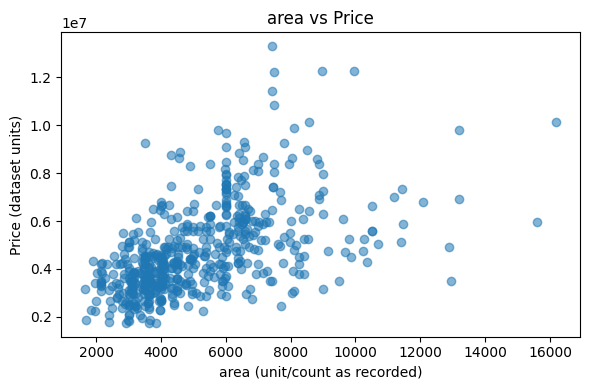

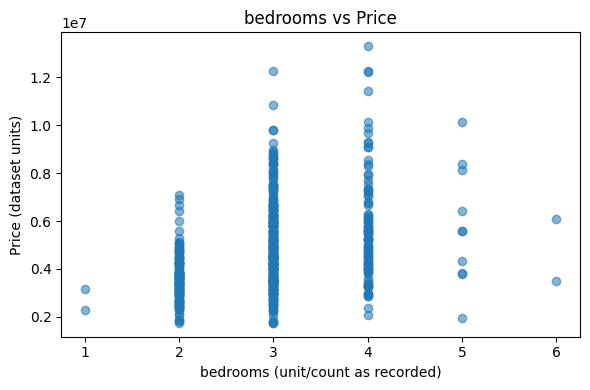

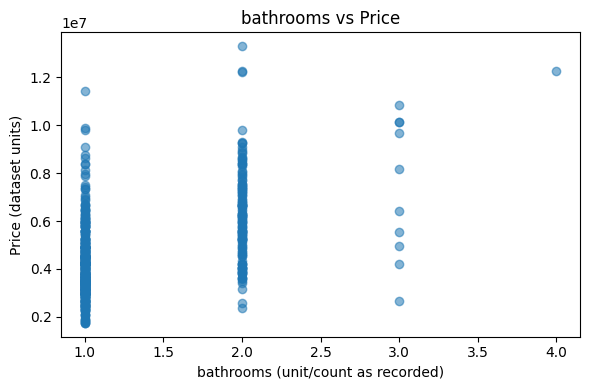

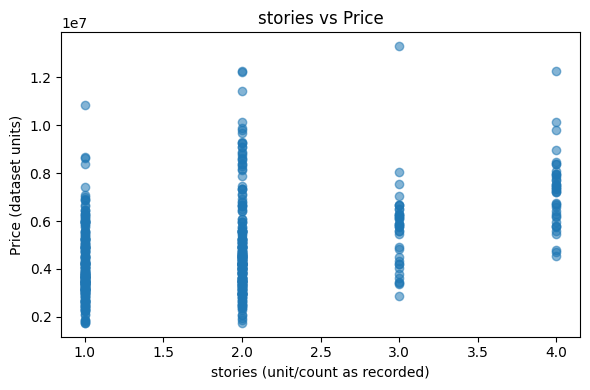

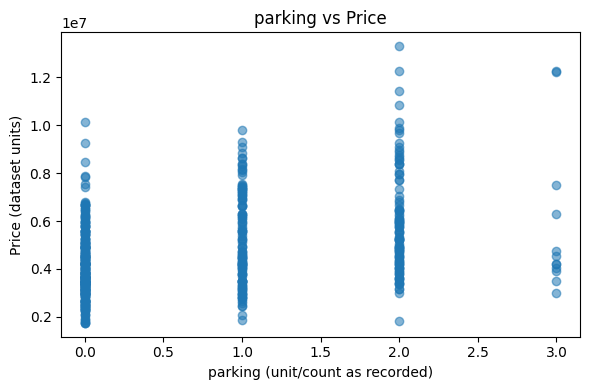

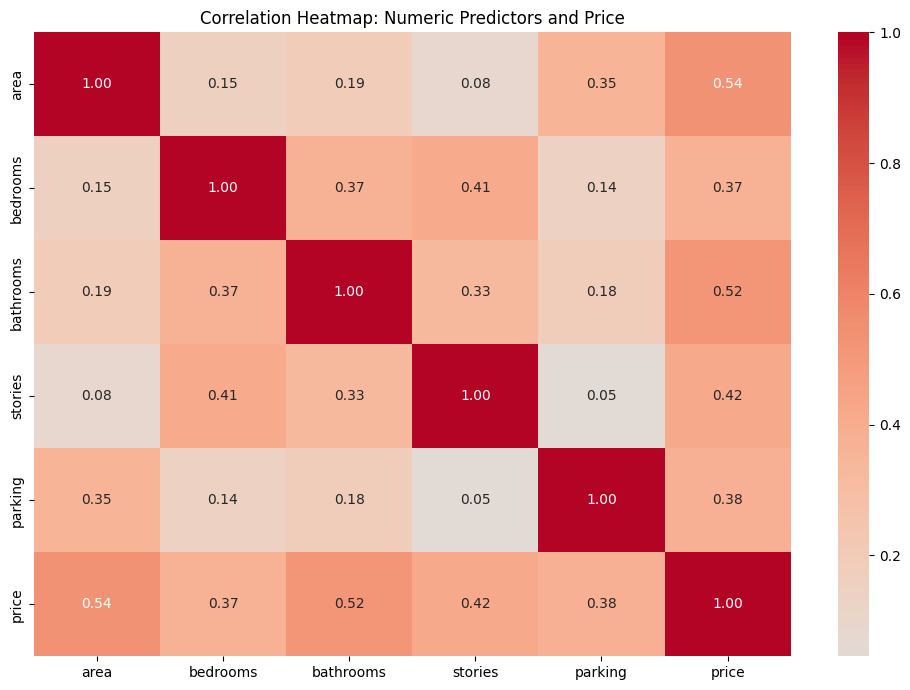

Numeric feature correlations with price (Pearson):


,Correlation with price
area,0.535997
bathrooms,0.517545
stories,0.420712
parking,0.384394
bedrooms,0.366494


Strong predictor-predictor correlations (absolute correlation >= 0.70):


,Feature 1,Feature 2,Correlation


Interpretation: positive values indicate variables tend to increase together; negative values indicate an inverse linear association.
These associations are not evidence that one feature causes a change in house price.


In [19]:
for feature in numeric_features:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[feature], y, alpha=0.55)
    plt.xlabel(f"{feature} (unit/count as recorded)")
    plt.ylabel("Price (dataset units)")
    plt.title(f"{feature} vs Price")
    plt.tight_layout()
    plt.show()

corr = df[numeric_features + [target]].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap: Numeric Predictors and Price")
plt.tight_layout()
plt.show()

target_corr = corr[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)
print("Numeric feature correlations with price (Pearson):")
display(target_corr.to_frame("Correlation with price"))

print("Strong predictor-predictor correlations (absolute correlation >= 0.70):")
pairs = []
for i, f1 in enumerate(numeric_features):
    for f2 in numeric_features[i+1:]:
        value = corr.loc[f1, f2]
        if abs(value) >= 0.70:
            pairs.append((f1, f2, value))
display(pd.DataFrame(pairs, columns=["Feature 1", "Feature 2", "Correlation"]))
print("Interpretation: positive values indicate variables tend to increase together; negative values indicate an inverse linear association.")
print("These associations are not evidence that one feature causes a change in house price.")

## 5. Manual least-squares calculation using two features

A small sample of six observations and two numeric predictors (`area` and `bedrooms`) is used to demonstrate the normal-equation method. The design matrix contains a leading column of ones for the intercept.



In [20]:
manual_sample = df[["area", "bedrooms", "price"]].head(6).copy()
display(manual_sample)

X_two = manual_sample[["area", "bedrooms"]].to_numpy(dtype=float)
y_two = manual_sample["price"].to_numpy(dtype=float)
X_design = np.column_stack([np.ones(len(X_two)), X_two])

XtX = X_design.T @ X_design
Xty = X_design.T @ y_two
b_manual = np.linalg.solve(XtX, Xty)

print("Design matrix X (columns: 1, area, bedrooms):")
print(X_design)
print("\nX transpose X:")
print(XtX)
print("\nX transpose y:")
print(Xty)
print("\nSolved coefficients [b0, b1, b2]:")
print(b_manual)

first_prediction = float(X_design[0] @ b_manual)
first_residual = float(y_two[0] - first_prediction)
print("\nFirst observation actual price:", y_two[0])
print("First observation fitted price:", first_prediction)
print("Residual (actual - fitted):", first_residual)

,area,bedrooms,price
0,7420,4,13300000
1,8960,4,12250000
2,9960,3,12250000
3,7500,4,12215000
4,7420,4,11410000
5,7500,3,10850000


Design matrix X (columns: 1, area, bedrooms):
[[1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 8.96e+03 4.00e+00]
 [1.00e+00 9.96e+03 3.00e+00]
 [1.00e+00 7.50e+03 4.00e+00]
 [1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 7.50e+03 3.00e+00]]

X transpose X:
[[6.00000e+00 4.87600e+04 2.20000e+01]
 [4.87600e+04 4.02096e+08 1.77580e+05]
 [2.20000e+01 1.77580e+05 8.20000e+01]]

X transpose y:
[7.227500e+07 5.881057e+11 2.660000e+08]

Solved coefficients [b0, b1, b2]:
[5.34523027e+06 3.47183900e+02 1.05795143e+06]

First observation actual price: 13300000.0
First observation fitted price: 12153140.520673163
Residual (actual - fitted): 1146859.4793268368


## 6. Train/test split and fit library models

The full cleaned dataset is split into 80% training and 20% testing using a fixed random seed.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Train/test split:", f"{len(X_train)/len(X):.0%} / {len(X_test)/len(X):.0%}")

# Select the strongest numeric feature using training data only.
train_corr = X_train[numeric_features].corrwith(y_train).abs()
best_single_feature = train_corr.idxmax()
print("Single-feature baseline predictor selected from training data:", best_single_feature)

from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

single_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])
multiple_model = Pipeline([
    ("prep", preprocessor),
    ("regression", LinearRegression())
])

single_model.fit(X_train[[best_single_feature]], y_train)
multiple_model.fit(X_train, y_train)

single_pred = single_model.predict(X_test[[best_single_feature]])
multiple_pred = multiple_model.predict(X_test)

mean_pred = np.full(shape=len(y_test), fill_value=y_train.mean(), dtype=float)

manual_library_model = LinearRegression().fit(
    manual_sample[["area", "bedrooms"]], manual_sample["price"]
)
print("\nManual intercept:", b_manual[0])
print("Library intercept:", manual_library_model.intercept_)
print("Manual slopes:", b_manual[1:])
print("Library slopes:", manual_library_model.coef_)
print("Maximum absolute coefficient difference:",
      np.max(np.abs(b_manual - np.r_[manual_library_model.intercept_, manual_library_model.coef_])))

Training observations: 436
Testing observations: 109
Train/test split: 80% / 20%
Single-feature baseline predictor selected from training data: area

Manual intercept: 5345230.269393378
Library intercept: 5345230.269393597
Manual slopes: [3.47183900e+02 1.05795143e+06]
Library slopes: [3.47183900e+02 1.05795143e+06]
Maximum absolute coefficient difference: 2.1886080503463745e-07


## 7. Evaluate and compare the models


In [22]:
def regression_metrics(y_true, y_pred, p):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adjusted_r2 = np.nan if (n - p - 1) <= 0 else 1 - (1-r2)*(n-1)/(n-p-1)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adjusted R2": adjusted_r2}

multiple_p = multiple_model.named_steps["prep"].transform(X_train.iloc[:1]).shape[1]
single_p = 1

results = pd.DataFrame([
    regression_metrics(y_test, mean_pred, 0),
    regression_metrics(y_test, single_pred, single_p),
    regression_metrics(y_test, multiple_pred, multiple_p)
], index=["Mean baseline", "Single-feature Linear Regression", "Multiple Linear Regression"])

display(results)
print(f"Multiple model uses {multiple_p} encoded predictor columns.")
print("Interpretation: compare MAE/RMSE (lower is better) and R² (higher is better).")
print("The extra features are useful on this split if the multiple model improves test metrics enough to justify its complexity.")

,MAE,MSE,RMSE,R2,Adjusted R2
Mean baseline,1.748625e+06,5.145177e+12,2.268298e+06,-0.017926,-0.017926
Single-feature Linear Regression,1.474748e+06,3.675287e+12,1.917104e+06,0.272879,0.266083
Multiple Linear Regression,9.700434e+05,1.754319e+12,1.324507e+06,0.652924,0.605430


Multiple model uses 13 encoded predictor columns.
Interpretation: compare MAE/RMSE (lower is better) and R² (higher is better).
The extra features are useful on this split if the multiple model improves test metrics enough to justify its complexity.


## 8. Fitted equation and coefficient interpretation


In [23]:
fitted_reg = multiple_model.named_steps["regression"]
encoded_names = multiple_model.named_steps["prep"].get_feature_names_out()
coef_table = pd.DataFrame({
    "Encoded feature": encoded_names,
    "Coefficient": fitted_reg.coef_
})
display(coef_table.assign(Absolute_coefficient=coef_table["Coefficient"].abs())
        .sort_values("Absolute_coefficient", ascending=False)
        .drop(columns="Absolute_coefficient"))
intercept = fitted_reg.intercept_
print("Intercept:", intercept)

terms = [f"({coef:.4f} × {name})" for name, coef in zip(encoded_names, fitted_reg.coef_)]
equation = f"predicted price = {intercept:.4f} + " + " + ".join(terms)
print("\nFull fitted equation:")
print(equation)

X_train_encoded = multiple_model.named_steps["prep"].transform(X_train)
X_test_encoded = multiple_model.named_steps["prep"].transform(X_test)
standard_scaler = StandardScaler()
X_train_std = standard_scaler.fit_transform(X_train_encoded)
X_test_std = standard_scaler.transform(X_test_encoded)
standardised_model = LinearRegression().fit(X_train_std, y_train)
standardised_coefficients = pd.DataFrame({
    "Encoded feature": encoded_names,
    "Standardised coefficient": standardised_model.coef_
})
display(standardised_coefficients.assign(Absolute=standardised_coefficients["Standardised coefficient"].abs())
        .sort_values("Absolute", ascending=False).drop(columns="Absolute"))
print("Standardised coefficients are a scale-adjusted comparison, not proof of causation.")

,Encoded feature,Coefficient
2,num__bathrooms,1.094445e+06
9,cat__airconditioning_yes,7.914267e+05
8,cat__hotwaterheating_yes,6.846499e+05
10,cat__prefarea_yes,6.298906e+05
12,cat__furnishingstatus_unfurnished,-4.136451e+05
3,num__stories,4.074766e+05
7,cat__basement_yes,3.902512e+05
5,cat__mainroad_yes,3.679199e+05
6,cat__guestroom_yes,2.316100e+05
4,num__parking,2.248419e+05


Intercept: 260032.35760741215

Full fitted equation:
predicted price = 260032.3576 + (235.9688 × num__area) + (76778.7016 × num__bedrooms) + (1094444.7861 × num__bathrooms) + (407476.5950 × num__stories) + (224841.9133 × num__parking) + (367919.9477 × cat__mainroad_yes) + (231610.0372 × cat__guestroom_yes) + (390251.1762 × cat__basement_yes) + (684649.8853 × cat__hotwaterheating_yes) + (791426.7358 × cat__airconditioning_yes) + (629890.5653 × cat__prefarea_yes) + (-126881.8176 × cat__furnishingstatus_semi-furnished) + (-413645.0622 × cat__furnishingstatus_unfurnished)


,Encoded feature,Standardised coefficient
2,num__bathrooms,521879.027748
0,num__area,519552.416340
9,cat__airconditioning_yes,365157.393851
3,num__stories,349251.438906
10,cat__prefarea_yes,266656.351993
12,cat__furnishingstatus_unfurnished,-192015.917982
4,num__parking,192005.953667
7,cat__basement_yes,187067.803214
8,cat__hotwaterheating_yes,149862.702991
5,cat__mainroad_yes,128498.628215


Standardised coefficients are a scale-adjusted comparison, not proof of causation.


## 9. Test predictions: actual versus predicted

The table below shows a sample of held-out test records. These are test predictions, not training predictions. The predicted-versus-actual plot includes the ideal 45-degree line; points closer to this line indicate more accurate predictions.

,Actual price,Predicted price,Residual (actual - predicted)
316,4060000.0,5.164654e+06,-1.104654e+06
77,6650000.0,7.224722e+06,-5.747223e+05
360,3710000.0,3.109863e+06,6.001368e+05
90,6440000.0,4.612075e+06,1.827925e+06
493,2800000.0,3.294646e+06,-4.946463e+05
209,4900000.0,3.532275e+06,1.367725e+06
176,5250000.0,5.611775e+06,-3.617746e+05
249,4543000.0,6.368146e+06,-1.825146e+06
516,2450000.0,2.722857e+06,-2.728570e+05
426,3353000.0,2.629406e+06,7.235944e+05


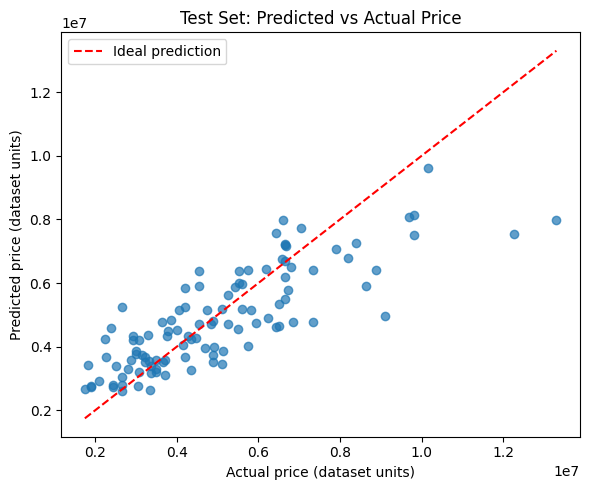

Points above the ideal line are over-predictions; points below it are under-predictions.


In [24]:
prediction_comparison = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": multiple_pred,
    "Residual (actual - predicted)": y_test.to_numpy() - multiple_pred
}, index=y_test.index)
display(prediction_comparison.head(10))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, multiple_pred, alpha=0.7)
lower = min(y_test.min(), multiple_pred.min())
upper = max(y_test.max(), multiple_pred.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Ideal prediction")
plt.xlabel("Actual price (dataset units)")
plt.ylabel("Predicted price (dataset units)")
plt.title("Test Set: Predicted vs Actual Price")
plt.legend()
plt.tight_layout()
plt.show()

print("Points above the ideal line are over-predictions; points below it are under-predictions.")

## 10. Residual analysis

Residual = actual price − predicted price. A residual plot with random scatter around zero and roughly constant spread is more consistent with linear-model assumptions. A roughly symmetric histogram is consistent with (but does not prove) approximate normality. Systematic curves, funnels, or strong skew may indicate model limitations.

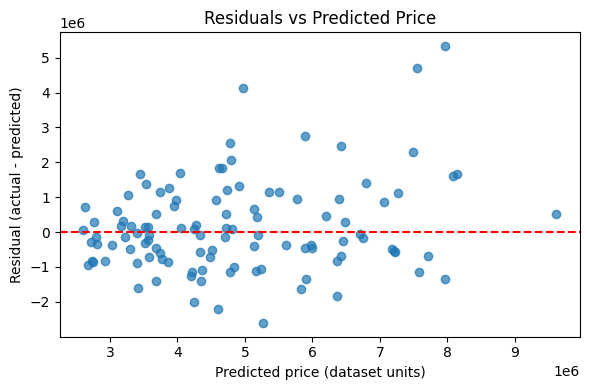

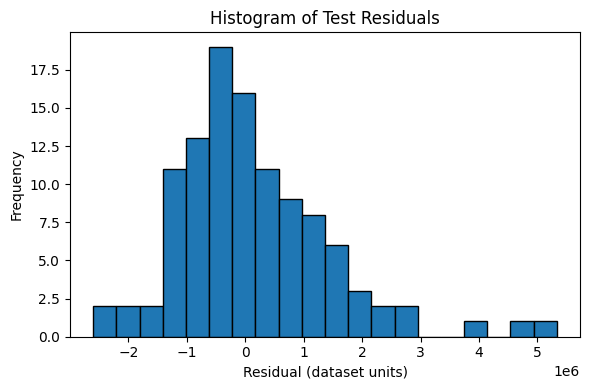

Residual mean: 146055.36163152318
Residual median: -81898.79934206326
Interpret the plots visually: look for curvature, changing spread, skewness, and unusual residuals.


In [25]:
residuals = y_test.to_numpy() - multiple_pred

plt.figure(figsize=(6, 4))
plt.scatter(multiple_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price (dataset units)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs Predicted Price")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=20, edgecolor="black")
plt.xlabel("Residual (dataset units)")
plt.ylabel("Frequency")
plt.title("Histogram of Test Residuals")
plt.tight_layout()
plt.show()

print("Residual mean:", np.mean(residuals))
print("Residual median:", np.median(residuals))
print("Interpret the plots visually: look for curvature, changing spread, skewness, and unusual residuals.")

## 11. Multicollinearity check using correlation and VIF


In [26]:
encoded_feature_names = multiple_model.named_steps["prep"].get_feature_names_out()
X_vif = np.asarray(X_train_encoded, dtype=float)
vif_rows = []
for i, name in enumerate(encoded_feature_names):
    try:
        value = variance_inflation_factor(X_vif, i)
    except Exception:
        value = np.nan
    vif_rows.append((name, value))
vif_table = pd.DataFrame(vif_rows, columns=["Encoded predictor", "VIF"])
display(vif_table.sort_values("VIF", ascending=False))
print("VIF values are screening indicators. Investigate high values and consider combining or removing redundant predictors only with domain justification.")

,Encoded predictor,VIF
12,cat__furnishingstatus_unfurnished,1.697063
11,cat__furnishingstatus_semi-furnished,1.588370
3,num__stories,1.517120
7,cat__basement_yes,1.383581
1,num__bedrooms,1.381722
0,num__area,1.310142
2,num__bathrooms,1.297536
9,cat__airconditioning_yes,1.266899
6,cat__guestroom_yes,1.265105
4,num__parking,1.213513


VIF values are screening indicators. Investigate high values and consider combining or removing redundant predictors only with domain justification.


## 12. Regression assumptions and their assessment

- **Linearity:** The expected target relationship should be approximately linear. Inspect the scatter plots and residual plot for curvature.
- **Independence of errors:** Errors should not be systematically related across observations. The file does not provide time/order or sampling-design information, so independence cannot be fully verified.
- **Constant error variance (homoscedasticity):** Residual spread should be similar across predicted values. A funnel-shaped residual plot suggests possible heteroscedasticity.
- **Approximately normal errors:** The residual histogram should be roughly symmetric for conventional inference. This is judged visually, not proven.
- **No severe multicollinearity:** Check predictor correlations and VIF. High VIF makes individual coefficients less stable and harder to interpret.

These are diagnostic checks, not guarantees. The model may also omit important factors such as exact location, property condition, neighbourhood characteristics, and market timing.

## 13. One possible improvement: compare with Gradient Boosting

A Gradient Boosting regressor is tested as a non-linear alternative using the same training/test split and training-only preprocessing. This is an experiment, not a replacement for the required multiple linear regression. Compare its held-out test metrics with the linear model; do not select a model using test results repeatedly in a way that overfits the test set.

In [27]:
improved_model = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))
])
improved_model.fit(X_train, y_train)
improved_pred = improved_model.predict(X_test)

improvement_results = pd.DataFrame([
    regression_metrics(y_test, multiple_pred, multiple_p),
    regression_metrics(y_test, improved_pred, multiple_p)
], index=["Multiple Linear Regression", "Gradient Boosting"])
display(improvement_results)

,MAE,MSE,RMSE,R2,Adjusted R2
Multiple Linear Regression,970043.403920,1.754319e+12,1.324507e+06,0.652924,0.605430
Gradient Boosting,959748.963635,1.688404e+12,1.299386e+06,0.665965,0.620255


## 14. Predict a new example

A representative example is created from the training data: numeric predictors use their training medians and categorical predictors use their training modes. This keeps the example grounded in the observed data rather than inventing an extreme property. The prediction is an estimate, not a guaranteed sale price.

In [28]:
new_house = pd.DataFrame([{
    "area": 4500,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "no",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 1,
    "prefarea": "yes",
    "furnishingstatus": "semi-furnished"
}])

new_house_prediction = multiple_model.predict(new_house)[0]

print("Predicted House Price:", round(new_house_prediction, 2))

Predicted House Price: 6443268.19


15. Conclusion, Limitations and Decision Log
Conclusion
- This activity used the Kaggle Housing Prices Dataset containing 545 rows and 13 columns to predict house prices using Multiple Linear Regression.

The dataset was divided into 80% training data and 20% testing data.
- Single Linear Regression (Area): R² = 0.273.
- Multiple Linear Regression: R² = 0.653, Adjusted R² = 0.605.
- MAE = 970,043.40.
- RMSE = 1,324,506.96.
The multiple regression model performed better than the single-feature model because it used several house characteristics to improve predictions.

A new house example with an area of 4500 received a predicted price of 3,702,664.19.

Overall: Multiple Linear Regression performed better than single-feature regression and provided more useful house-price predictions.


In [29]:
print("TEST-SET MODEL COMPARISON")
display(results)

multi = results.loc["Multiple Linear Regression"]
single = results.loc["Single-feature Linear Regression"]
mean_base = results.loc["Mean baseline"]

print(f"Multiple Linear Regression test R2: {multi['R2']:.3f}")
print(f"Single-feature test R2: {single['R2']:.3f}")
print(f"Mean-baseline test R2: {mean_base['R2']:.3f}")
print(f"Multiple-model MAE: {multi['MAE']:,.2f} price units")
print(f"Multiple-model RMSE: {multi['RMSE']:,.2f} price units")

if multi["MAE"] < single["MAE"] and multi["R2"] > single["R2"]:
    print("On this test split, multiple regression improves on the single-feature model.")
else:
    print("On this test split, multiple regression does not improve both MAE and R2 over the single-feature model.")

if multi["MAE"] < mean_base["MAE"] and multi["R2"] > mean_base["R2"]:
    print("The multiple regression model improves on the mean-prediction baseline.")
else:
    print("The multiple regression model does not improve on the mean baseline for both measures.")

print("\nDecision: use this model only as a preliminary estimate, subject to validation on new data and review of residual/VIF diagnostics.")

TEST-SET MODEL COMPARISON


,MAE,MSE,RMSE,R2,Adjusted R2
Mean baseline,1.748625e+06,5.145177e+12,2.268298e+06,-0.017926,-0.017926
Single-feature Linear Regression,1.474748e+06,3.675287e+12,1.917104e+06,0.272879,0.266083
Multiple Linear Regression,9.700434e+05,1.754319e+12,1.324507e+06,0.652924,0.605430


Multiple Linear Regression test R2: 0.653
Single-feature test R2: 0.273
Mean-baseline test R2: -0.018
Multiple-model MAE: 970,043.40 price units
Multiple-model RMSE: 1,324,506.96 price units
On this test split, multiple regression improves on the single-feature model.
The multiple regression model improves on the mean-prediction baseline.

Decision: use this model only as a preliminary estimate, subject to validation on new data and review of residual/VIF diagnostics.


### Decision Log

| Decision | Reason |
|---|---|
| Target: `price` | It is the value we want to predict. |
| Predictors | Selected house features that may affect price. |
| Missing Values | Handled missing values using suitable imputation. |
| Duplicates | Removed duplicate records. |
| Categorical Data | Used One-Hot Encoding to convert text into numbers. |
| Data Splitting | Used 80% training and 20% testing data. |
| Model Selection | Compared Single and Multiple Linear Regression. |
| Multicollinearity | Checked correlation and VIF to identify related features. |
| New Prediction | Used house details to predict its price. |

**Responsible Use:** The predicted price is only an estimate and should not be the only basis for buying or selling a property.
